# Setup

This notebook teaches you to read a neighbourhood from open data: its streets, blocks, buildings and everyday places,
measured with the same methods urban researchers use. It compares four places with very different histories: the
centre of Belfast, Barcelona's planned Eixample, the Walled City of Lahore and the new town of Craigavon. You can then
point it at your own street by changing one line.

Libraries: **OSMnx** downloads OpenStreetMap data and turns streets into a graph; **NetworkX** does the graph
mathematics (shortest paths, centrality); **GeoPandas** holds buildings and places as tables with shapes; **momepy**
measures urban form; **matplotlib** draws. In Colab the first cell installs what is missing.

In [1]:
import importlib.util, subprocess, sys
for pkg in ("osmnx", "momepy"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import momepy
import matplotlib.pyplot as plt

Path("data").mkdir(exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = "data/cache"
ox.settings.log_console = False
plt.rcParams.update({"figure.dpi": 100})
print("osmnx", ox.__version__, "| networkx", nx.__version__, "| momepy", momepy.__version__)

# The four places: (latitude, longitude) of a centre point. Change or add your own here.
PLACES = {
    "Belfast centre": (54.5973, -5.9301),
    "Barcelona Eixample": (41.3917, 2.1649),
    "Lahore Walled City": (31.5820, 74.3150),
    "Craigavon (Brownlow)": (54.4475, -6.3870),
}
RADIUS = 800          # metres: each study area is the square 1.6 km across around the point

osmnx 2.1.2 | networkx 3.7 | momepy 1.0.0


# What urban form is

**Urban form**, or **urban morphology**, is the physical shape of a settlement: how its streets, plots, blocks and
buildings are arranged. The idea is old. The geographer M. R. G. Conzen, studying Alnwick in 1960, split a town plan
into three layers that change at different speeds: the **street system** (slowest: streets last for centuries), the
**plot pattern** (land ownership parcels) and the **buildings** (fastest: rebuilt every few decades). The Italian
school (Muratori, Caniggia) read building **types** and how they grow. Space syntax (Hillier and Hanson, 1984) studied
how the **configuration** of streets shapes movement.

Today these ideas are measured. A street network is a **graph**: junctions are **nodes**, street segments **edges**.
Buildings are polygons with areas, perimeters and heights. From these come numbers that can be compared between any
two places on Earth, and that is what this notebook does. A few words used throughout:

- **Urban fabric:** the texture made by streets, blocks and buildings together, as you see it on a map.
- **Block:** land surrounded by streets. **Grain:** fine grain means many small blocks and buildings; coarse grain few large ones.
- **Permeability:** how many ways there are through an area on foot. **Connectivity:** how well streets join up.
- **Density:** a quantity per area: buildings, floor space, people, junctions.

Numbers do not replace walking a street. They let you ask sharper questions of it: why is this place more walkable
than that one, what changed and when, what is missing. Each measure below comes with how to read it and what it
cannot tell you.

# Getting the data: OpenStreetMap

**OpenStreetMap** (OSM) is a map of the world made by volunteers, free to use under the Open Database Licence. It
stores three kinds of element: **nodes** (points with a latitude and longitude), **ways** (ordered lists of nodes:
streets, building outlines) and **relations** (groups). Each carries **tags**, key = value pairs that say what it is:
`highway=residential`, `building=yes`, `building:levels=4`, `amenity=school`. Everything we measure depends on these
tags, so their **completeness** varies by place and must always be checked.

OSMnx asks the **Overpass API** for the data within a distance of a point and returns a street **graph** (for walking,
`network_type="walk"`, which includes footpaths) and tables of **features** (buildings, amenities). The graph is
**projected** to a local metric coordinate system (UTM) so that lengths come out in metres.

We download **two** graphs for each place. The **walking graph** includes footpaths, and in cities where pavements
and crossings are mapped as separate ways it splits every street into many short pieces, so it suits questions about
walking (route directness, access) but exaggerates junction counts. The **street graph** (`drive_service`: roads and
service lanes) describes the layout of streets themselves and is used for structure, orientation and centrality.

Belfast centre         walk graph:  2423 nodes  street graph:  1019 nodes  buildings  3317  other features 1424


Barcelona Eixample     walk graph:  2324 nodes  street graph:   315 nodes  buildings  3368  other features 4163


Lahore Walled City     walk graph:  4408 nodes  street graph:  3745 nodes  buildings   471  other features  212


Craigavon (Brownlow)   walk graph:  1571 nodes  street graph:  1020 nodes  buildings   881  other features  418


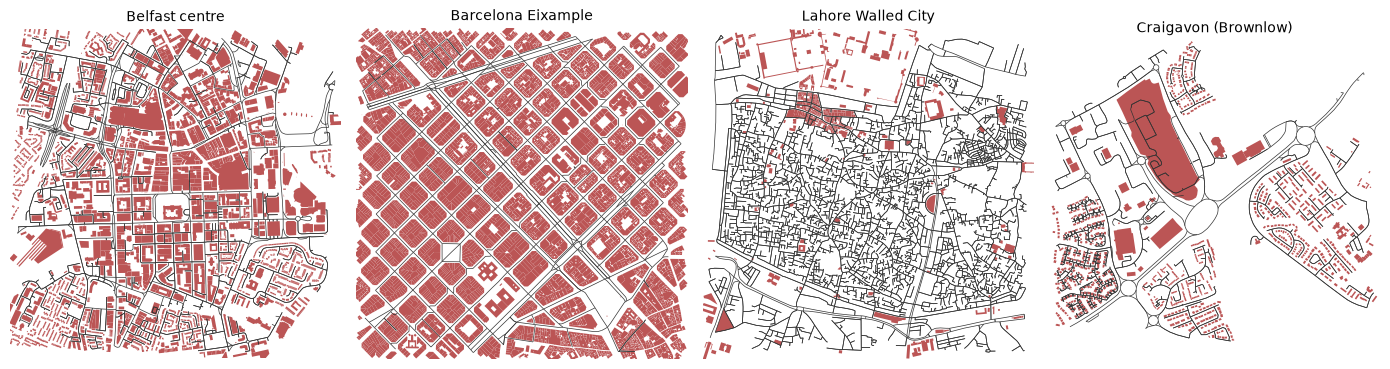

In [2]:
SERVERS = ["https://overpass-api.de/api", "https://overpass.private.coffee/api", "https://maps.mail.ru/osm/tools/overpass/api"]


def patient(fn, *args, **kw):
    """Public Overpass servers are shared and sometimes busy: retry with growing waits, trying each server in turn."""
    import time
    for attempt in range(8):
        ox.settings.overpass_url = SERVERS[attempt % len(SERVERS)]
        try:
            return fn(*args, **kw)
        except Exception as e:
            if "No data elements" in str(e):
                raise
            time.sleep(min(60, 5 * 2 ** (attempt // len(SERVERS))))
    raise RuntimeError("Overpass servers busy; run the cell again later")


def fetch(name, latlon):
    G = patient(ox.graph_from_point, latlon, dist=RADIUS, dist_type="bbox", network_type="walk", simplify=True)
    G = ox.project_graph(G)
    tags = {"building": True, "amenity": True, "shop": True, "leisure": ["park", "playground"],
            "public_transport": "platform", "highway": "bus_stop", "railway": ["station", "tram_stop"]}
    F = patient(ox.features_from_point, latlon, tags, dist=RADIUS)
    F = F.to_crs(G.graph["crs"])
    D = ox.project_graph(patient(ox.graph_from_point, latlon, dist=RADIUS, dist_type="bbox", network_type="drive_service"),
                         to_crs=G.graph["crs"])
    return G, F, D


data, drive = {}, {}
for name, latlon in PLACES.items():
    G, F, D = fetch(name, latlon)
    data[name], drive[name] = (G, F), D
    nb = int(F["building"].notna().sum()) if "building" in F else 0
    print(f"{name:22s} walk graph: {G.number_of_nodes():5d} nodes  street graph: {D.number_of_nodes():5d} nodes  "
          f"buildings {nb:5d}  other features {len(F) - nb:4d}")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, (G, F)) in zip(axes, data.items()):
    b = F[F["building"].notna()] if "building" in F else F.iloc[:0]
    b[b.geom_type.isin(["Polygon", "MultiPolygon"])].plot(ax=ax, color="#b55", linewidth=0)
    ox.plot_graph(drive[name], ax=ax, node_size=0, edge_color="#333", edge_linewidth=0.5, show=False, close=False, bgcolor="white")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

The printout counts what was downloaded for each 1.6 km square. The two graphs differ most in Barcelona: 2,324 nodes
for walking but only 315 for streets, because pavements and crossings there are mapped as separate ways. Belfast and
Barcelona each have over 3,300 buildings, while the Walled City of Lahore, one of the densest places in South Asia, has
only 470. That is not the city; it is the map. Most of Lahore's buildings have not yet been traced in OpenStreetMap, so
every building measure for Lahore below is about the mapped part only, a lesson in checking coverage before believing a
number. The maps show the street graph in black over mapped buildings in red: Barcelona's grid of square blocks,
Belfast's mixture, Lahore's dense mesh of lanes with few buildings drawn, and Craigavon's loops and branches.

# Streets as a graph

Here we use the street graph. In it each **node** is a junction or a dead end, each **edge** a street segment between two nodes. The number
of streets meeting at a node is its **degree**; OSMnx counts **streets per node** without double-counting two-way
edges. From these come the basic network measures:

- **Intersection density:** junctions (nodes with 3 or more streets) per km². Higher means smaller blocks and more
  choice of route. Values above about 100 per km² are typical of walkable centres.
- **Street density:** km of street per km².
- **Mean streets per node:** 4 in a perfect grid, about 3 where T-junctions dominate, lower where there are many dead ends.
- **Share of dead ends (degree 1):** cul-de-sacs; high in post-war suburbs.
- **Mean edge length:** a proxy for block size.

In [3]:
def area_km2(G):
    xs = [d["x"] for _, d in G.nodes(data=True)]; ys = [d["y"] for _, d in G.nodes(data=True)]
    return (max(xs) - min(xs)) * (max(ys) - min(ys)) / 1e6


rows = {}
for name, G in drive.items():
    A = area_km2(G)
    spn = pd.Series(dict(G.nodes(data="street_count")))
    Gu = ox.convert.to_undirected(G)
    L = sum(d["length"] for *_, d in Gu.edges(data=True)) / 1000
    rows[name] = {
        "area km²": A,
        "intersections per km²": (spn >= 3).sum() / A,
        "street km per km²": L / A,
        "mean streets per node": spn.mean(),
        "dead ends %": 100 * (spn == 1).mean(),
        "4-way %": 100 * (spn == 4).mean(),
        "mean edge length m": np.mean([d["length"] for *_, d in Gu.edges(data=True)]),
    }
streets = pd.DataFrame(rows).T
print(streets.round(1).to_string())

                      area km²  intersections per km²  street km per km²  mean streets per node  dead ends %  4-way %  mean edge length m
Belfast centre             2.6                  275.0               21.7                    2.5         28.9      9.7                44.9
Barcelona Eixample         2.5                  117.2               17.3                    3.5          5.7     51.4                86.6
Lahore Walled City         2.6                  935.0               41.1                    2.3         36.1      4.4                24.4
Craigavon (Brownlow)       2.4                  235.9               14.5                    2.2         43.6      2.7                32.2


Read the table column by column. **Streets per node** separates the patterns: 3.5 in the Eixample, where half of
all nodes (51 %) are four-way crossings, against 2.2 to 2.5 elsewhere. **Dead ends** are rare in Barcelona (6 %) and
common in Craigavon (44 %), the cul-de-sac signature. Lahore's Walled City has by far the most junctions, 935 per km²,
and the shortest street segments (24 m): its lanes (*galis*) branch and meet every few metres, and over a third (36 %)
end blindly in courtyards, which is the classic organic pattern. Barcelona has the fewest junctions (117 per km²) and the
longest segments (87 m) because its blocks are large, 113 m squares. So intersection density alone does not mean
walkable: a fine organic mesh and a coarse grid can both work well on foot, and a suburb can have many junctions that
all lead to dead ends.

# Orientation and order

Which way do the streets point? For each edge take its compass **bearing** (0° north, 90° east), count both directions
(a street running north also runs south), and gather them into 36 bins of 10°. A **rose diagram** shows the result: a
grid gives four petals; an unplanned or curving fabric gives a near circle.

**Orientation entropy** (Boeing 2019) measures the disorder: H = −Σ p_i ln p_i over the 36 bins. A perfect four-way
grid has H = ln 4 ≈ 1.386; streets spread evenly over all directions have H = ln 36 ≈ 3.584. **Orientation order**
rescales it from 0 (disorder) to 1 (perfect grid): φ = 1 − ((H − 1.386)/(3.584 − 1.386))².

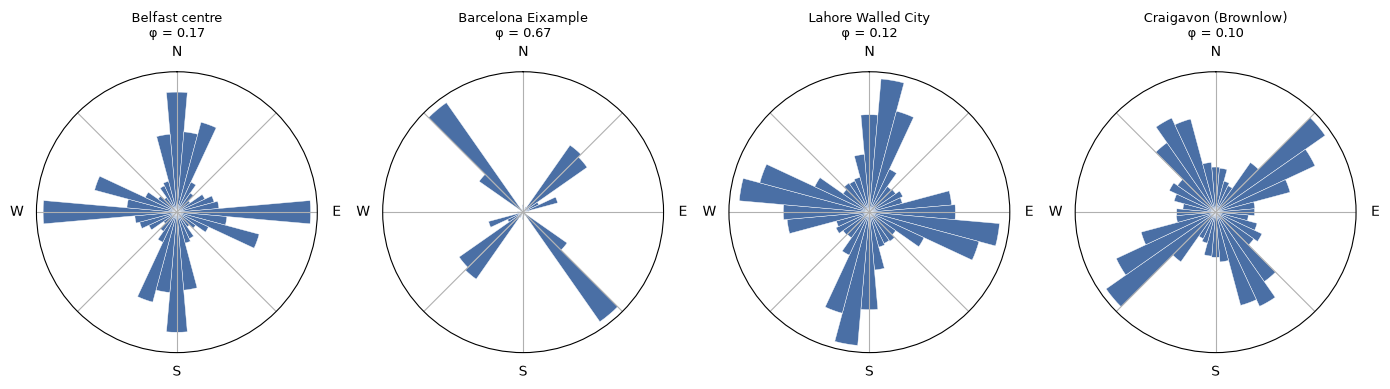

                      orientation entropy  orientation order φ
Belfast centre                      3.387                0.171
Barcelona Eixample                  2.658                0.665
Lahore Walled City                  3.444                0.123
Craigavon (Brownlow)                3.474                0.097


In [4]:
def orientation(G):
    Gu = ox.convert.to_undirected(ox.bearing.add_edge_bearings(ox.project_graph(G, to_latlong=True)))
    b = np.array([d["bearing"] for *_, d in Gu.edges(data=True) if not np.isnan(d.get("bearing", np.nan))])
    w = np.array([d["length"] for *_, d in Gu.edges(data=True) if not np.isnan(d.get("bearing", np.nan))])
    both = np.concatenate([b, (b + 180) % 360]); ww = np.concatenate([w, w])
    counts, _ = np.histogram((both + 5) % 360, bins=36, range=(0, 360), weights=ww)   # bins centred on 0, 10, ...
    p = counts / counts.sum()
    H = -(p[p > 0] * np.log(p[p > 0])).sum()
    phi = 1 - ((H - np.log(4)) / (np.log(36) - np.log(4))) ** 2
    return counts, H, phi


fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), subplot_kw={"projection": "polar"})
for ax, (name, G) in zip(axes, drive.items()):
    counts, H, phi = orientation(G)
    streets.loc[name, "orientation entropy"] = H
    streets.loc[name, "orientation order φ"] = phi
    th = np.radians(np.arange(0, 360, 10))
    ax.bar(th, counts / counts.max(), width=np.radians(10), color="#4a6fa5", edgecolor="white", linewidth=0.3)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_yticks([]); ax.set_xticklabels(["N", "", "E", "", "S", "", "W", ""])
    ax.set_title(f"{name}\nφ = {phi:.2f}", fontsize=9)
plt.tight_layout(); plt.show()
print(streets[["orientation entropy", "orientation order φ"]].round(3).to_string())

The roses show the difference at a glance. Barcelona's streets point in two directions, about 45° and 135°,
because Cerdà's grid is turned from north to follow the coast; its orientation order is 0.67. It is not 1 because each
block has its corners cut off (the *xamfrans*), adding short diagonal edges, and because the old city and the Avinguda
Diagonal cross the square. Belfast (0.17), Lahore (0.12) and Craigavon (0.10) all point every way. The entropy cannot
tell an old organic core from a planned curving suburb, since both are disordered in direction: Lahore and Craigavon
score almost the same. A single measure reads one property; telling patterns apart needs several together.

# Circuity and route directness

How far out of the way do streets take you? **Circuity** is the total length of street edges divided by the total
straight-line distance between their end nodes: 1 for straight streets, higher for curving ones. A stronger test is
**route directness**: pick pairs of places at random, find the shortest route along streets with **Dijkstra's
algorithm** (NetworkX `shortest_path_length`), and divide by the straight-line distance between them. A ratio of 1.3
means walking 30 % further than the crow flies. Grids score about 1.2 to 1.3; cul-de-sac layouts can exceed 1.6.

In [5]:
rng = np.random.default_rng(1)
for name, (G, F) in data.items():
    Gu = ox.convert.to_undirected(G)
    streets.loc[name, "edge circuity"] = ox.stats.circuity_avg(Gu)
    big = Gu.subgraph(max(nx.connected_components(Gu), key=len))
    nodes = np.array(list(big.nodes))
    xy = np.array([[big.nodes[n]["x"], big.nodes[n]["y"]] for n in nodes])
    ratios = []
    while len(ratios) < 300:
        i, j = rng.integers(0, len(nodes), 2)
        crow = np.hypot(*(xy[i] - xy[j]))
        if 400 < crow < 1200:                                   # walks of 5 to 15 minutes
            ratios.append(nx.shortest_path_length(big, nodes[i], nodes[j], weight="length") / crow)
    streets.loc[name, "route directness (median)"] = np.median(ratios)
    streets.loc[name, "routes > 1.5x crow"] = 100 * np.mean(np.array(ratios) > 1.5)
print(streets[["edge circuity", "route directness (median)", "routes > 1.5x crow"]].round(2).to_string())

                      edge circuity  route directness (median)  routes > 1.5x crow
Belfast centre                 1.06                       1.32               18.33
Barcelona Eixample             1.02                       1.26                4.67
Lahore Walled City             1.07                       1.29               11.67
Craigavon (Brownlow)           1.07                       1.81               84.33


Edge circuity is close to 1 everywhere (1.02 to 1.07): individual streets are nearly straight, even in Lahore.
Route directness, measured on the walking graph for 300 random walks of 400 to 1,200 m, separates the places sharply.
The median walk in Barcelona is 1.26 times the straight-line distance, in Lahore 1.29 and in Belfast 1.32. In Craigavon
it is 1.81, and 84 % of walks are more than 1.5 times as long as the crow flies, against 5 % in Barcelona. That is the
cost of cul-de-sacs for people on foot: the house across the fence may be ten minutes away. Lahore's crooked lanes still
give fairly direct routes because there are so many of them; what matters for walking is the choice of paths, not how
straight each one is.

# Centrality: which streets matter most

Some streets carry more through-movement than others because of where they sit in the network, not because of what is
on them. **Betweenness centrality** of a node is the share of all shortest paths between other pairs of nodes that pass
through it. High-betweenness streets are the natural main streets: where shops survive and traffic gathers. **Closeness
centrality** is the inverse of the average distance to every other node: high in the middle, low at the edges.
Computing betweenness exactly is slow for big graphs, so we estimate it from 400 sampled sources (`k=400`).

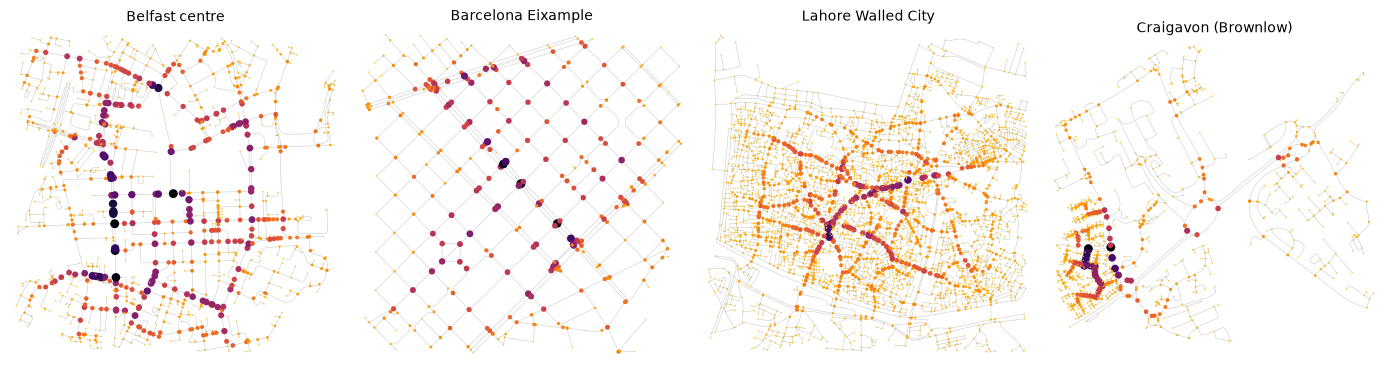

                      betweenness: top 5% share
Belfast centre                             0.26
Barcelona Eixample                         0.16
Lahore Walled City                         0.40
Craigavon (Brownlow)                       0.45


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, G) in zip(axes, drive.items()):
    Gu = ox.convert.to_undirected(G)
    bc = nx.betweenness_centrality(Gu, k=min(400, len(Gu)), weight="length", seed=1)
    vals = np.array(list(bc.values()))
    top = np.sort(vals)[::-1]
    streets.loc[name, "betweenness: top 5% share"] = top[: max(1, len(top) // 20)].sum() / top.sum()
    mx = max(vals.max(), 1e-12)
    nc = [plt.cm.inferno_r(0.15 + 0.85 * bc[n] / mx) for n in Gu.nodes]
    ns = [1 + 40 * bc[n] / mx for n in Gu.nodes]
    ox.plot_graph(Gu, ax=ax, node_size=ns, node_color=nc, node_zorder=2, edge_color="#ccc", edge_linewidth=0.4,
                  show=False, close=False, bgcolor="white")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()
print(streets[["betweenness: top 5% share"]].round(2).to_string())

On the maps, larger and darker nodes carry the most shortest paths. The table gives the share of all betweenness
held by the top 5 % of nodes: a measure of how concentrated movement is. In Barcelona it is lowest (16 %): in a regular
grid many routes are equally short, so movement spreads over many streets. In Lahore (40 %) and Craigavon (45 %) a few
links carry most through-movement: the bazaar spines of the Walled City, and the distributor road of the new town. The
same number means different things: in Lahore the busy spines are lined with shops, which is the old logic of the
bazaar; in Craigavon they are roads designed to carry cars past homes.

# Buildings: grain, density and the Spacematrix

Building footprints give the **grain** of a place (how big the buildings are) and its **density**. Berghauser Pont and
Haupt's **Spacematrix** (2010) describes density with three linked numbers:

- **GSI**, ground space index or coverage: building footprint area ÷ land area.
- **FSI**, floor space index: total floor area (footprint × floors) ÷ land area.
- **L**, mean number of floors = FSI ÷ GSI. And **OSR**, open space ratio = (1 − GSI) ÷ FSI: open ground per unit of floor.

Low-rise sprawl has low GSI and low FSI; a dense historic centre has high GSI and middling FSI; towers in a park have
low GSI and high FSI. Floors come from the OSM tags `building:levels`, or `height` ÷ 3 m; where neither is tagged we
must assume a value, and the share assumed is reported.

                      buildings  per hectare  median footprint m²  floors tagged %  assumed floors   GSI   FSI  L floors   OSR
Belfast centre           3316.0        12.95                52.71            33.87             2.0  0.33  1.01      3.07  0.67
Barcelona Eixample       3353.0        13.10               345.80            59.86             7.0  0.59  4.23      7.14  0.10
Lahore Walled City        470.0         1.84                89.30             1.06             2.0  0.05  0.11      2.00  8.65
Craigavon (Brownlow)      881.0         3.44               111.07             0.91             2.0  0.13  0.25      1.96  3.55


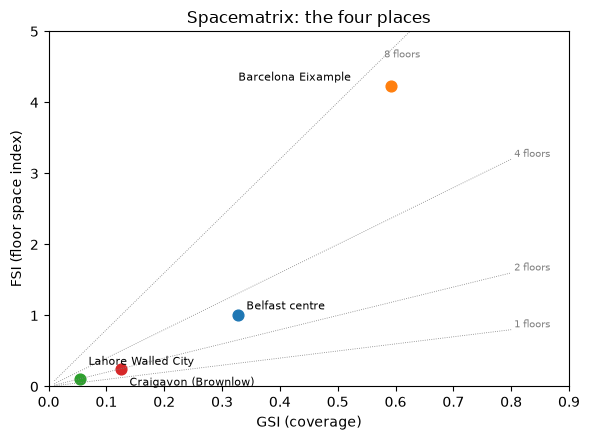

In [7]:
def floors(row):
    for key in ("building:levels",):
        if key in row and pd.notna(row[key]):
            try:
                return float(str(row[key]).split(";")[0]), True
            except ValueError:
                pass
    if "height" in row and pd.notna(row["height"]):
        try:
            return max(1.0, round(float(str(row["height"]).replace("m", "").split(";")[0]) / 3)), True
        except ValueError:
            pass
    return np.nan, False


bstats, blds = {}, {}
for name, (G, F) in data.items():
    b = F[F["building"].notna() & F.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    fl = b.apply(floors, axis=1, result_type="expand"); b["floors"], b["tagged"] = fl[0], fl[1].astype(bool)
    default = b.loc[b.tagged, "floors"].median() if b.tagged.mean() > 0.2 else 2.0
    b["floors_used"] = b["floors"].fillna(default)
    b["area"] = b.area
    blds[name] = b
    land = (2 * RADIUS) ** 2
    gsi = b.area.sum() / land
    fsi = (b.area * b.floors_used).sum() / land
    bstats[name] = {"buildings": len(b), "per hectare": len(b) / (land / 1e4), "median footprint m²": b.area.median(),
                    "floors tagged %": 100 * b.tagged.mean(), "assumed floors": default,
                    "GSI": gsi, "FSI": fsi, "L floors": fsi / gsi, "OSR": (1 - gsi) / fsi}
bstats = pd.DataFrame(bstats).T
print(bstats.round(2).to_string())

fig, ax = plt.subplots(figsize=(6, 4.5))
offsets = {"Belfast centre": (6, 4), "Barcelona Eixample": (-110, 4), "Lahore Walled City": (6, 10), "Craigavon (Brownlow)": (6, -12)}
for name, r in bstats.iterrows():
    ax.scatter(r.GSI, r.FSI, s=60); ax.annotate(name, (r.GSI, r.FSI), fontsize=8, xytext=offsets.get(name, (4, 4)), textcoords="offset points")
g = np.linspace(0.01, 0.8, 50)
for L in (1, 2, 4, 8):
    ax.plot(g, g * L, color="grey", lw=0.6, ls=":")
    xl = min(0.8, 4.6 / L); ax.text(xl, xl * L, f" {L} floors", fontsize=7, color="grey", va="bottom")
ax.set_xlim(0, 0.9); ax.set_ylim(0, 5); ax.set_xlabel("GSI (coverage)"); ax.set_ylabel("FSI (floor space index)")
ax.set_title("Spacematrix: the four places"); plt.tight_layout(); plt.show()

The Spacematrix table and chart place the four areas. The Eixample covers 59 % of its land with buildings
(GSI 0.59), at a median footprint of 346 m² (whole blocks of joined apartment buildings) and a floor space index of 4.2:
about seven floors on average, with 60 % of buildings carrying a floors tag. Little open ground remains per unit of
floor (OSR 0.10). Central Belfast has a third of its land covered, an FSI of 1.0 and about three floors; floors are
tagged for a third of buildings, so the rest assume the tagged median of 2. Craigavon is low-rise and open: GSI 0.13,
FSI 0.25, under 2 floors. Lahore's figures (GSI 0.05) are an artefact: with most buildings unmapped and almost no floors
tagged (1 %), its true coverage is far higher. Always read the 'floors tagged %' and building count before the density.

# Morphometrics: the shape of each building

momepy measures many properties of individual elements. Three useful ones for buildings:

- **Elongation:** the ratio of the short to the long side of the smallest rotated rectangle around the footprint
  (1 = square, near 0 = long and thin, like a terrace row).
- **Circular compactness:** footprint area ÷ area of the smallest enclosing circle (1 for a circle, low for L- and
  courtyard-shaped buildings).
- **Shared walls ratio:** the share of the perimeter touching another building. High in terraces and historic
  cores where buildings are joined; zero for detached houses.

                        area  elongation  compactness  shared walls  joined to a neighbour %
Belfast centre         53.08        0.62         0.54          0.37                    86.55
Barcelona Eixample    346.16        0.47         0.43          0.57                    98.03
Lahore Walled City     89.34        0.65         0.53          0.50                    71.43
Craigavon (Brownlow)  111.09        0.75         0.57          0.00                    29.89


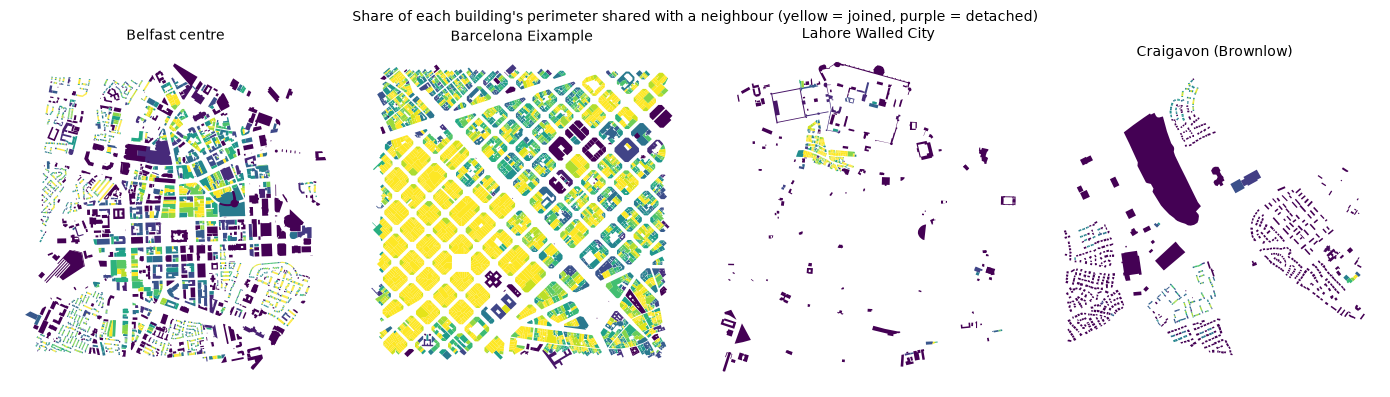

In [8]:
morph = {}
for name, b in blds.items():
    b = b.reset_index(drop=True)
    b = b[b.is_valid & (b.area > 10)].copy()
    b["elongation"] = momepy.elongation(b)
    b["compactness"] = momepy.circular_compactness(b)
    b["shared walls"] = momepy.shared_walls(b) / b.length
    blds[name] = b
    morph[name] = b[["area", "elongation", "compactness", "shared walls"]].median()
    morph[name]["joined to a neighbour %"] = 100 * (b["shared walls"] > 0.05).mean()
morph = pd.DataFrame(morph).T
print(morph.round(2).to_string())

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, b) in zip(axes, blds.items()):
    b.plot(column="shared walls", ax=ax, cmap="viridis", vmin=0, vmax=0.6, linewidth=0)
    ax.set_title(name, fontsize=10); ax.set_axis_off()
plt.suptitle("Share of each building's perimeter shared with a neighbour (yellow = joined, purple = detached)", fontsize=10)
plt.tight_layout(); plt.show()

The medians describe a typical building in each place. Barcelona's buildings are large (346 m²) and joined:
98 % share part of their outline with a neighbour, and on average 57 % of a building's perimeter is a party wall. That
is the perimeter block: continuous street walls around a courtyard. Belfast's terraces show the same habit at smaller
size (53 m², 87 % joined). In Craigavon the median building shares no wall at all, and only 30 % touch a neighbour,
mostly semi-detached pairs: detached and semi-detached houses on their own plots. Craigavon's buildings are also the
most nearly square (elongation 0.75). The maps show these differences as colour: yellow continuous blocks against
purple free-standing houses.

# Access: the 15-minute question

Can you reach daily needs on foot? Take the centre of each study area, find all street nodes within 15 minutes' walk
(1,200 m at 80 m a minute) along the network with Dijkstra's algorithm, build the **isochrone** (the area reachable),
and count the everyday places inside it by kind. The walking distance is along streets, not as the crow flies, so a
circuitous layout reaches less.

In [9]:
KINDS = {
    "food shop": lambda r: r.get("shop") in ("supermarket", "convenience", "greengrocer", "bakery", "butcher", "general"),
    "school": lambda r: r.get("amenity") in ("school", "kindergarten"),
    "health": lambda r: r.get("amenity") in ("pharmacy", "doctors", "clinic", "hospital", "dentist"),
    "food and drink": lambda r: r.get("amenity") in ("restaurant", "cafe", "fast_food", "pub"),
    "park or play": lambda r: r.get("leisure") in ("park", "playground"),
    "transit stop": lambda r: r.get("highway") == "bus_stop" or r.get("public_transport") == "platform" or r.get("railway") in ("station", "tram_stop"),
    "worship": lambda r: r.get("amenity") == "place_of_worship",
}
access = {}
for name, (G, F) in data.items():
    Gu = ox.convert.to_undirected(G)
    xs = np.array([d["x"] for _, d in Gu.nodes(data=True)]); ys = np.array([d["y"] for _, d in Gu.nodes(data=True)])
    centre = ox.distance.nearest_nodes(Gu, xs.mean(), ys.mean())
    reach = nx.single_source_dijkstra_path_length(Gu, centre, cutoff=1200, weight="length")
    pts = gpd.GeoSeries(gpd.points_from_xy([Gu.nodes[n]["x"] for n in reach], [Gu.nodes[n]["y"] for n in reach]), crs=F.crs)
    iso = pts.union_all().convex_hull.buffer(50)
    P = F[F.representative_point().within(iso)]
    rec = {k: int(sum(bool(f(r)) for r in P.to_dict("records"))) for k, f in KINDS.items()}
    rec["isochrone km²"] = iso.area / 1e6
    rec["kinds present (of 7)"] = sum(rec[k] > 0 for k in KINDS)
    access[name] = rec
access = pd.DataFrame(access).T
print(access.round(2).to_string())

                      food shop  school  health  food and drink  park or play  transit stop  worship  isochrone km²  kinds present (of 7)
Belfast centre             41.0     3.0    11.0           234.0          11.0          85.0     19.0           2.51                   7.0
Barcelona Eixample        203.0    29.0   119.0           946.0          23.0         178.0     17.0           2.80                   7.0
Lahore Walled City          1.0     8.0     5.0            11.0          29.0           1.0    110.0           2.59                   7.0
Craigavon (Brownlow)        5.0     0.0     0.0             8.0           0.0          10.0      2.0           1.47                   4.0


From the centre of each area, the reachable area in 15 minutes is about 2.5 to 2.8 km² in the three older
places but only 1.5 km² in Craigavon, because its routes are indirect. Barcelona's isochrone holds 203 food shops,
119 health places and 946 places to eat or drink: everyday needs on every block. Central Belfast has all seven kinds
too. Craigavon's centre reaches only four of the seven kinds, with no school, health place or park mapped within the
walk. Lahore reaches all seven, with 110 places of worship, but only one food shop, which is implausible for one of the
busiest bazaars in Pakistan and again reflects mapping, not reality. Counts are only as good as the tags: check a few
against what you know.

# Neighbourhood types from the data

Can the computer tell kinds of fabric apart? Divide one larger area into a grid of 250 m cells, measure each cell
(intersections, building count and coverage, median footprint, shared walls, dead-end share), standardise the measures
so each has mean 0 and standard deviation 1, and group similar cells with **k-means clustering**. The clusters are not
labelled by the computer: you name them by reading their average values and looking at the map. This is how
urban-form typologies (for example the momepy-based classifications of whole countries) are built.

      buildings  coverage  median footprint  shared walls  junctions  dead ends  cells
type                                                                                  
0         135.5      0.22             51.84          0.35       17.0        9.0    150
1          18.0      0.31            390.06          0.10       14.5        5.5     44
2         316.5      0.32             47.16          0.51       18.0        5.0     70
3          84.0      0.15             54.36          0.26        5.0        3.0     92
4          11.0      0.06            134.96          0.02        2.0        1.0     39


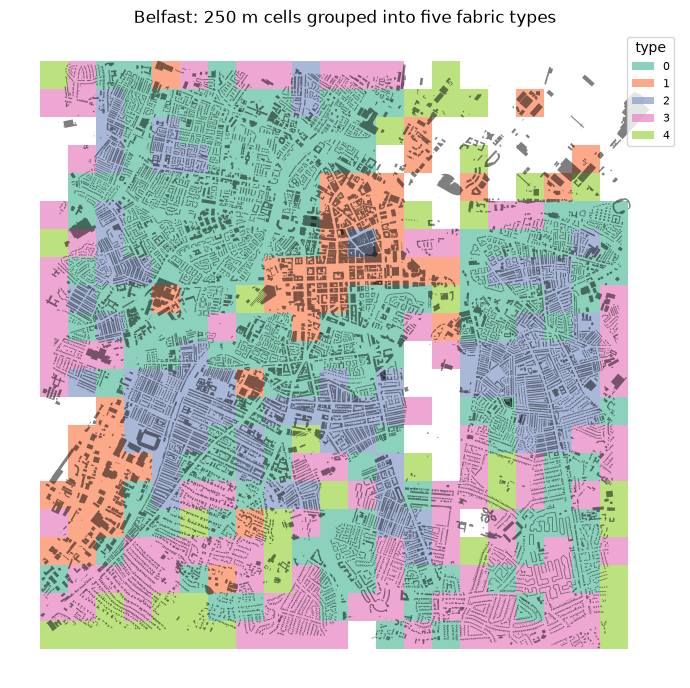

In [10]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

city_pt, city_r = (54.5900, -5.9300), 2500                       # Belfast, 5 km across
Gc = ox.project_graph(patient(ox.graph_from_point, city_pt, dist=city_r, dist_type="bbox", network_type="drive_service"))
Bc = patient(ox.features_from_point, city_pt, {"building": True}, dist=city_r).to_crs(Gc.graph["crs"])
Bc = Bc[Bc.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index(drop=True)
Bc = Bc[Bc.is_valid].copy()
Bc["sw"] = momepy.shared_walls(Bc) / Bc.length
nodes_c = ox.graph_to_gdfs(Gc, edges=False)
x0, y0, x1, y1 = Bc.total_bounds
size = 250
cells = gpd.GeoDataFrame(geometry=[__import__("shapely").box(x, y, x + size, y + size)
                                   for x in np.arange(x0, x1, size) for y in np.arange(y0, y1, size)], crs=Bc.crs)
cent = Bc.copy(); cent["geometry"] = Bc.representative_point(); cent["a"] = Bc.area
j = gpd.sjoin(cent, cells, predicate="within")
g = j.groupby("index_right")
feat = pd.DataFrame({"buildings": g.size(), "coverage": g["a"].sum() / size ** 2,
                     "median footprint": g["a"].median(), "shared walls": g["sw"].mean()})
jn = gpd.sjoin(nodes_c, cells, predicate="within")
feat["junctions"] = jn[jn.street_count >= 3].groupby("index_right").size()
feat["dead ends"] = jn[jn.street_count == 1].groupby("index_right").size()
feat = feat.fillna(0)
feat = feat[feat.buildings >= 5]
X = StandardScaler().fit_transform(np.log1p(feat))
km = KMeans(n_clusters=5, n_init=20, random_state=0).fit(X)
feat["type"] = km.labels_
summary = feat.groupby("type").median().round(2)
summary["cells"] = feat.groupby("type").size()
print(summary.to_string())

cells_t = cells.join(feat["type"], how="inner")
fig, ax = plt.subplots(figsize=(7, 7))
cells_t.plot(column="type", categorical=True, cmap="Set2", ax=ax, alpha=0.75, legend=True, legend_kwds={"title": "type", "fontsize": 8})
Bc.plot(ax=ax, color="black", linewidth=0, alpha=0.5)
ax.set_axis_off(); ax.set_title("Belfast: 250 m cells grouped into five fabric types"); plt.tight_layout(); plt.show()

The table gives the median of each measure in each type, and the map shows where the types fall. Reading them,
with names we give, not the computer:

- **Type 2, dense terraces:** about 316 buildings per cell, small footprints (47 m²) and the most shared walls (0.51):
  the Victorian terraced streets around the centre.
- **Type 0, terraced and semi-detached housing:** fewer buildings (136), still small and partly joined (0.35).
- **Type 3, suburban housing:** lower coverage (0.15), few junctions (5 per cell): later, looser estates.
- **Type 1, large buildings:** few but big footprints (390 m²) at high coverage (0.31): the commercial centre, retail,
  hospitals and industry.
- **Type 4, open land with scattered buildings:** coverage 0.06: parks, docks, the edges.

The number of types (five) is a choice: try 4 or 7 and see which split is most meaningful. The types come from the data,
but their meaning comes from you.

# Reading responsibly

Every number above rests on what volunteers have mapped. Before trusting a figure, ask:

- **Coverage:** are all buildings mapped? Compare with satellite imagery for a few blocks. Are floors or heights tagged
  for most buildings, or are we assuming? (The table in the Buildings section reports this.)
- **Edges:** a square study area cuts streets and blocks at its border; measures near the edge are biased.
- **Definitions:** a 'walk' network includes footpaths that a 'drive' network lacks; dead ends for cars may be through
  routes on foot. Say which you used.
- **Population:** OSM holds no population counts. Use a census or a gridded product (WorldPop, GHSL) for people per km².
- **The lived city:** numbers say nothing of safety, shade, noise, cost, who is welcome. Walk it, talk to people, read
  its history. Use the numbers to sharpen questions, not to end them.

**Questions to take to your own neighbourhood.** Change `PLACES` in the first cell to your street and run everything.
Is your area closer to a grid or to an organic pattern, and why (when was it built, by whom, over what)? Which street
has the highest betweenness, and is that where the shops are? How many of the seven everyday kinds can you reach in 15
minutes, and which is missing? Which fabric type is your home in, and what would it take to change it?

# What you have learned

- Urban form has layers that change at different speeds: streets, plots, buildings.
- OpenStreetMap stores the city as nodes, ways and tagged relations; OSMnx turns streets into a graph.
- Network measures (intersection density, streets per node, dead ends, orientation order, circuity, route directness,
  betweenness) describe how a street pattern works for movement.
- Building measures (GSI, FSI, floors, OSR, elongation, compactness, shared walls) describe grain and density.
- Network distance, not straight-line distance, decides what you can reach.
- Clustering many cells by their measures yields fabric types you then name and question.
- Every figure depends on mapping completeness, which must be checked and reported.